In [ ]:
!zip -r resunet_swinseg_basic_outputs.zip /content/resunet_swinseg_outputs

  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/ (stored 0%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/validation_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_per_image.png (deflated 17%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/dataset_split_manifest.csv (deflated 91%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_per_image.csv (deflated 42%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/validation_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnabl

In [1]:
!unzip -q /content/swinseg.zip -d /content/

In [4]:
import os
import random
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from google.colab import drive


SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
LEARNING_RATE = 1e-4
TEST_SIZE = 0.30
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5

DRIVE_ROOT = Path("/content/")
DATA_ROOT = DRIVE_ROOT
IMAGE_DIR = DATA_ROOT / "swinseg" / "images"
MASK_DIR = DATA_ROOT / "swinseg" / "GTmaps"
ZIP_PATH = DRIVE_ROOT / "swinseg.zip"
EXTRACT_DIR = Path("/content/swinseg")
OUTPUT_DIR = DRIVE_ROOT / "resunet_swinseg_outputs"

if not IMAGE_DIR.is_dir() or not MASK_DIR.is_dir():
    if ZIP_PATH.is_file():
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH, "r") as archive:
            archive.extractall(EXTRACT_DIR)
    search_roots = [DATA_ROOT, EXTRACT_DIR]
    candidates = [
        image_dir
        for root in search_roots if root.exists()
        for image_dir in root.rglob("images")
        if image_dir.is_dir() and (image_dir.parent / "masks").is_dir()
    ]
    unique_candidates = sorted(set(candidates))
    if len(unique_candidates) == 1:
        IMAGE_DIR = unique_candidates[0]
        MASK_DIR = IMAGE_DIR.parent / "masks"
    elif len(unique_candidates) > 1:
        raise RuntimeError(
            "More than one images/masks directory pair was found. "
            "Set IMAGE_DIR and MASK_DIR manually in this cell."
        )

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Image directory not found: {IMAGE_DIR}. Upload Our_data.zip to Google Drive "
        "or update IMAGE_DIR and MASK_DIR in this cell."
    )
if not MASK_DIR.is_dir():
    raise FileNotFoundError(
        f"Mask directory not found: {MASK_DIR}. Update MASK_DIR in this cell."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

physical_gpus = tf.config.list_physical_devices("GPU")
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print(f"GPU memory-growth configuration: {exc}")

print("TensorFlow:", tf.__version__)
print("Visible GPU(s):", physical_gpus if physical_gpus else "None; CPU will be used")
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)
print("Output directory:", OUTPUT_DIR)
print("Requested split: 70% train / 15% validation / 15% test")


TensorFlow: 2.21.0
Visible GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image directory: /content/swinseg/images
Mask directory: /content/swinseg/GTmaps
Output directory: /content/resunet_swinseg_outputs
Requested split: 70% train / 15% validation / 15% test


Total paired samples: 115
Image: 001.jpg
Mask:  001_GT.jpg

Image: 002.jpg
Mask:  002_GT.jpg

Image: 003.jpg
Mask:  003_GT.jpg

Image: 004.jpg
Mask:  004_GT.jpg

Image: 005.jpg
Mask:  005_GT.jpg

Train       :    80 images (69.57%)
Validation  :    17 images (14.78%)
Test        :    18 images (15.65%)
Total       : 115
Split manifest: /content/resunet_swinseg_outputs/dataset_split_manifest.csv


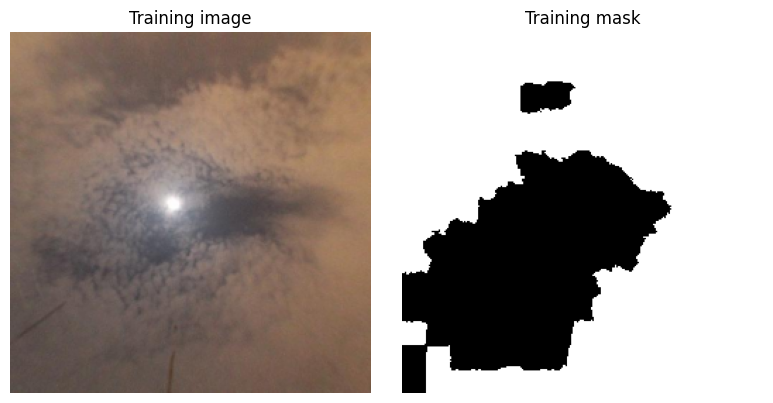

In [5]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_pairs(image_dir, mask_dir):
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    image_paths = sorted(
        os.path.join(image_dir, name)
        for name in os.listdir(image_dir)
        if os.path.splitext(name)[1].lower() in valid_exts
    )

    # Map masks using their corresponding image filename
    mask_map = {}

    for name in os.listdir(mask_dir):
        ext = os.path.splitext(name)[1].lower()

        if ext not in valid_exts:
            continue

        stem = os.path.splitext(name)[0]

        # Convert 001_GT to 001
        if stem.lower().endswith("_gt"):
            stem = stem[:-3]

        stem = stem.lower()
        mask_map[stem] = os.path.join(mask_dir, name)

    pairs = []

    for img_path in image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0].lower()

        if stem in mask_map:
            pairs.append((img_path, mask_map[stem]))
        else:
            print(f"Warning: no mask found for {img_path}")

    return pairs


pairs = get_pairs(IMAGE_DIR, MASK_DIR)

print("Total paired samples:", len(pairs))

for img, mask in pairs[:5]:
    print("Image:", os.path.basename(img))
    print("Mask: ", os.path.basename(mask))
    print()

def load_image_mask(image_path, mask_path):
    if isinstance(image_path, np.ndarray):
        image_path = image_path.item()
    if isinstance(mask_path, np.ndarray):
        mask_path = mask_path.item()
    image_path = os.fsdecode(image_path)
    mask_path = os.fsdecode(mask_path)

    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(
            f"Could not decode image file: {image_path}. "
            "Check that the file exists and is a valid image."
        )
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA
    )
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(
            f"Could not decode mask file: {mask_path}. "
            "Check that the file exists and is a valid image."
        )
    mask = cv2.resize(
        mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST
    )
    mask = (mask > 127).astype(np.float32)[..., np.newaxis]
    return image, mask

def tf_load_image_mask(image_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[image_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask

pairs = get_pairs(IMAGE_DIR, MASK_DIR)

train_pairs, holdout_pairs = train_test_split(
    pairs, test_size=TEST_SIZE, random_state=SEED, shuffle=True
)
val_pairs, test_pairs = train_test_split(
    holdout_pairs, test_size=0.50, random_state=SEED, shuffle=True
)

train_ids = {os.path.realpath(pair[0]) for pair in train_pairs}
val_ids = {os.path.realpath(pair[0]) for pair in val_pairs}
test_ids = {os.path.realpath(pair[0]) for pair in test_pairs}
all_ids = {os.path.realpath(pair[0]) for pair in pairs}

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert train_ids | val_ids | test_ids == all_ids
assert len(train_pairs) + len(val_pairs) + len(test_pairs) == len(pairs)

split_manifest = []
for split_name, split_pairs in (
    ("train", train_pairs),
    ("validation", val_pairs),
    ("test", test_pairs)
):
    for image_path, mask_path in split_pairs:
        split_manifest.append({
            "split": split_name,
            "image_name": Path(image_path).name,
            "image_path": image_path,
            "mask_path": mask_path
        })

manifest_path = OUTPUT_DIR / "dataset_split_manifest.csv"
pd.DataFrame(split_manifest).to_csv(manifest_path, index=False)

total_count = len(pairs)
for split_name, split_pairs in (
    ("Train", train_pairs),
    ("Validation", val_pairs),
    ("Test", test_pairs)
):
    print(
        f"{split_name:12s}: {len(split_pairs):5d} images "
        f"({100 * len(split_pairs) / total_count:.2f}%)"
    )
print("Total       :", total_count)
print("Split manifest:", manifest_path)

AUTOTUNE = tf.data.AUTOTUNE

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    return image, mask

def make_dataset(sample_pairs, training=False):
    if not sample_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")
    image_paths = [pair[0] for pair in sample_pairs]
    mask_paths = [pair[1] for pair in sample_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(sample_pairs),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs)
test_ds = make_dataset(test_pairs)

check_image, check_mask = load_image_mask(*train_pairs[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(check_image)
axes[0].set_title("Training image")
axes[1].imshow(check_mask[..., 0], cmap="gray")
axes[1].set_title("Training mask")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()


Model: "ResUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │      1,728 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        192 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_rel… │ (None, 256, 256,  │          0 │ encoder_block0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        256 │ encoder_block0_s… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │     36,864 │ encoder_block0_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_add  │ (None, 256, 256,  │          0 │ encoder_block0_s… │
│ (Add)               │ 64)               │            │ encoder_block0_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_a… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 256, 256,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │     73,728 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn2  │ (None, 128, 128,  │        512 │ encoder_block1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │      8,192 │ encoder_block0_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 128, 128,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │        512 │ encoder_block1_s… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │    147,456 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_add  │ (None, 128, 128,  │          0 │ encoder_block1_s

 Total params: 33,152,961 (126.47 MB)

 Trainable params: 33,133,505 (126.39 MB)

 Non-trainable params: 19,456 (76.00 KB)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step - binary_accuracy_logits: 0.7957 - dice_coef_logits: 0.7854 - iou_coef_logits: 0.6725 - loss: 0.5300
Epoch 1: val_dice_coef_logits improved from None to 0.63734, saving model to /content/resunet_swinseg_outputs/best_resunet.weights.h5

Epoch 1: finished saving model to /content/resunet_swinseg_outputs/best_resunet.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 98s 501ms/step - binary_accuracy_logits: 0.8553 - dice_coef_logits: 0.8444 - iou_coef_logits: 0.7448 - loss: 0.3694 - val_binary_accuracy_logits: 0.5471 - val_dice_coef_logits: 0.6373 - val_iou_coef_logits: 0.4809 - val_loss: 4.6951 - learning_rate: 1.0000e-04
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - binary_accuracy_logits: 0.8931 - dice_coef_logits: 0.8758 - iou_coef_logits: 0.7875 - loss: 0.2663
Epoch 2: val_dice_coef_logits improved from 0.63734 to 0.70881, saving model to /content/resunet_swinseg_outputs/best_resunet.weights.h5

Epoch 2: finished saving model to /content

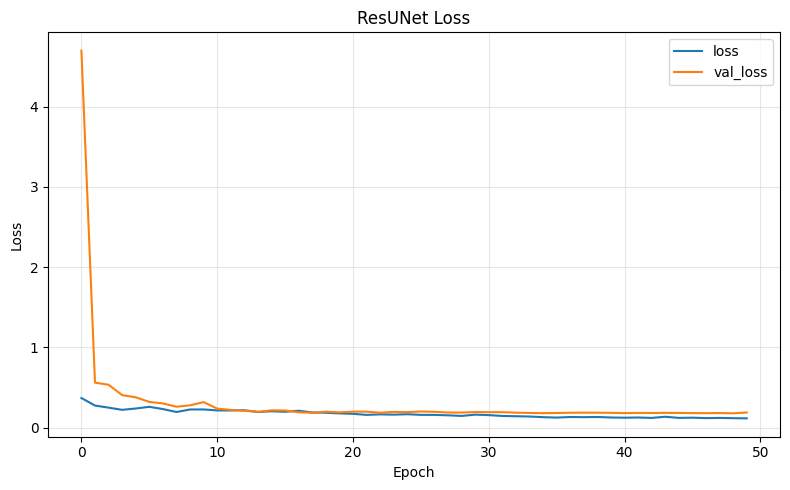

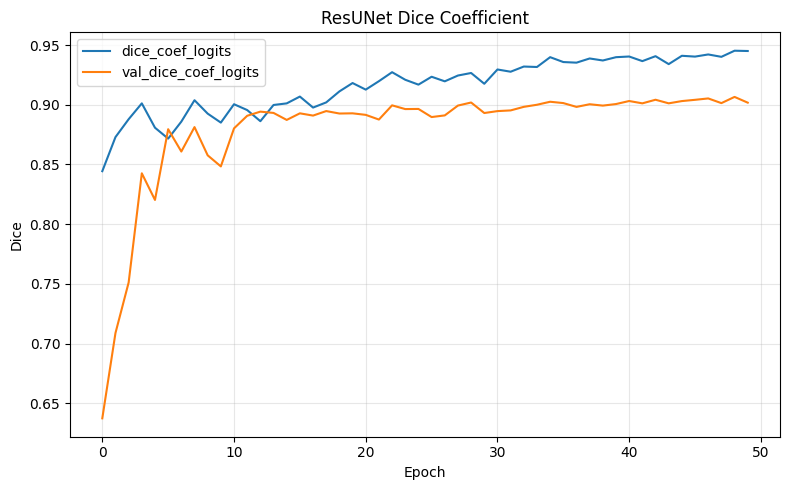

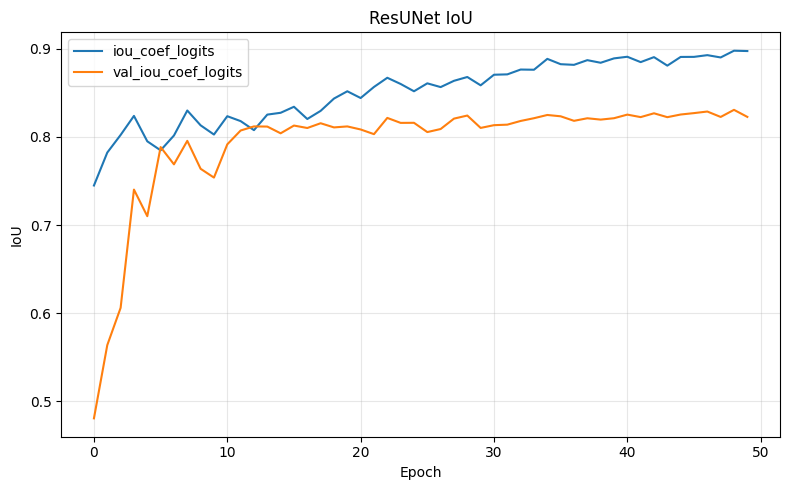

Best validation-selected weights: /content/resunet_swinseg_outputs/resunet_best.weights.h5
Training history: /content/resunet_swinseg_outputs/training_history.csv


In [6]:
def residual_block_initial(x, filters, strides=(1, 1), name="res_initial"):
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(x)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)
    shortcut = tf.keras.layers.Conv2D(
        filters, 1, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
    )(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])

def residual_block(x, filters, strides=(1, 1), name="res_block"):
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(y)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn2")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu2")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)

    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(
            filters, 1, strides=strides[0], padding="same", use_bias=False,
            kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
        )(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    else:
        shortcut = x

    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])

def build_resunet(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    inputs = tf.keras.Input(shape=input_shape, name="image")

    e0 = residual_block_initial(inputs, filters[0], name="encoder_block0")
    e1 = residual_block(e0, filters[1], strides=(2, 1), name="encoder_block1")
    e2 = residual_block(e1, filters[2], strides=(2, 1), name="encoder_block2")
    e3 = residual_block(e2, filters[3], strides=(2, 1), name="encoder_block3")
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name="bridge")

    d3 = tf.keras.layers.UpSampling2D(
        size=(2, 2), interpolation="bilinear", name="decoder_up3"
    )(bridge)
    d3 = tf.keras.layers.Concatenate(name="decoder_concat3")([d3, e3])
    d3 = residual_block(d3, filters[3], name="decoder_block3")

    d2 = tf.keras.layers.UpSampling2D(
        size=(2, 2), interpolation="bilinear", name="decoder_up2"
    )(d3)
    d2 = tf.keras.layers.Concatenate(name="decoder_concat2")([d2, e2])
    d2 = residual_block(d2, filters[2], name="decoder_block2")

    d1 = tf.keras.layers.UpSampling2D(
        size=(2, 2), interpolation="bilinear", name="decoder_up1"
    )(d2)
    d1 = tf.keras.layers.Concatenate(name="decoder_concat1")([d1, e1])
    d1 = residual_block(d1, filters[1], name="decoder_block1")

    d0 = tf.keras.layers.UpSampling2D(
        size=(2, 2), interpolation="bilinear", name="decoder_up0"
    )(d1)
    d0 = tf.keras.layers.Concatenate(name="decoder_concat0")([d0, e0])
    d0 = residual_block(d0, filters[0], name="decoder_block0")

    logits = tf.keras.layers.Conv2D(
        1, 1, padding="same", activation=None, name="segmentation_logits"
    )(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name="ResUNet")

def binary_predictions_from_logits(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.0, tf.float32)
    return y_true, y_pred

def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = binary_predictions_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

def dice_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = binary_predictions_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    denominator = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    return (2.0 * intersection + smooth) / (denominator + smooth)

def iou_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = binary_predictions_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    filters=PAPER_FILTERS
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits]
)
model.summary()

BEST_WEIGHTS_PATH = OUTPUT_DIR / "best_resunet.weights.h5"
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_WEIGHTS_PATH),
        monitor="val_dice_coef_logits",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef_logits",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef_logits",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

if not BEST_WEIGHTS_PATH.is_file():
    raise FileNotFoundError(f"Best checkpoint was not created: {BEST_WEIGHTS_PATH}")

model.load_weights(str(BEST_WEIGHTS_PATH))
FINAL_WEIGHTS_PATH = OUTPUT_DIR / "resunet_best.weights.h5"
model.save_weights(str(FINAL_WEIGHTS_PATH))

history_df = pd.DataFrame(history.history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index_label="epoch")

def save_history_plot(keys, title, ylabel, filename):
    available_keys = [key for key in keys if key in history.history]
    if not available_keys:
        return
    plt.figure(figsize=(8, 5))
    for key in available_keys:
        plt.plot(history.history[key], label=key)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

save_history_plot(["loss", "val_loss"], "ResUNet Loss", "Loss", "training_loss.png")
save_history_plot(
    ["dice_coef_logits", "val_dice_coef_logits"],
    "ResUNet Dice Coefficient", "Dice", "training_dice.png"
)
save_history_plot(
    ["iou_coef_logits", "val_iou_coef_logits"],
    "ResUNet IoU", "IoU", "training_iou.png"
)

print("Best validation-selected weights:", FINAL_WEIGHTS_PATH)
print("Training history:", OUTPUT_DIR / "training_history.csv")


validation: 1/17 005.jpg Dice=0.9358 IoU=0.8794
validation: 2/17 041.jpg Dice=0.9570 IoU=0.9175
validation: 3/17 031.jpg Dice=0.9247 IoU=0.8599
validation: 4/17 070.jpg Dice=0.9270 IoU=0.8640
validation: 5/17 079.jpg Dice=0.9508 IoU=0.9062
validation: 6/17 032.jpg Dice=0.7551 IoU=0.6066
validation: 7/17 016.jpg Dice=0.9346 IoU=0.8772
validation: 8/17 101.jpg Dice=0.8898 IoU=0.8015
validation: 9/17 013.jpg Dice=0.9618 IoU=0.9264
validation: 10/17 106.jpg Dice=0.8430 IoU=0.7286
validation: 11/17 094.jpg Dice=0.7705 IoU=0.6266
validation: 12/17 071.jpg Dice=0.9159 IoU=0.8449
validation: 13/17 095.jpg Dice=0.9270 IoU=0.8639
validation: 14/17 010.jpg Dice=0.9191 IoU=0.8504
validation: 15/17 067.jpg Dice=0.9372 IoU=0.8818
validation: 16/17 019.jpg Dice=0.9146 IoU=0.8426
validation: 17/17 045.jpg Dice=0.9068 IoU=0.8295

VALIDATION MACRO-AVERAGE METRICS
IoU                     : 0.8298 ± 0.0924
Recall                  : 0.9039 ± 0.0845
Precision               : 0.9136 ± 0.0851
Dice_Coefficient

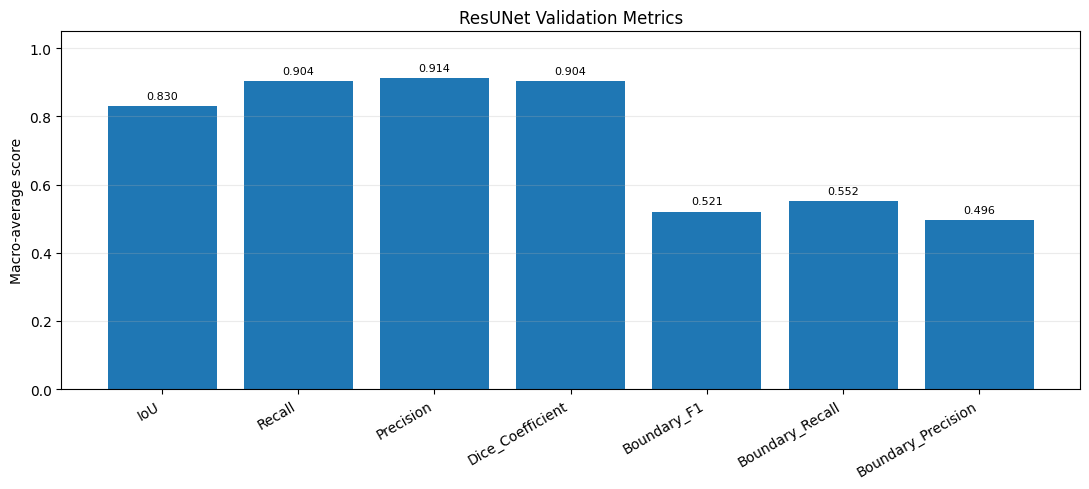

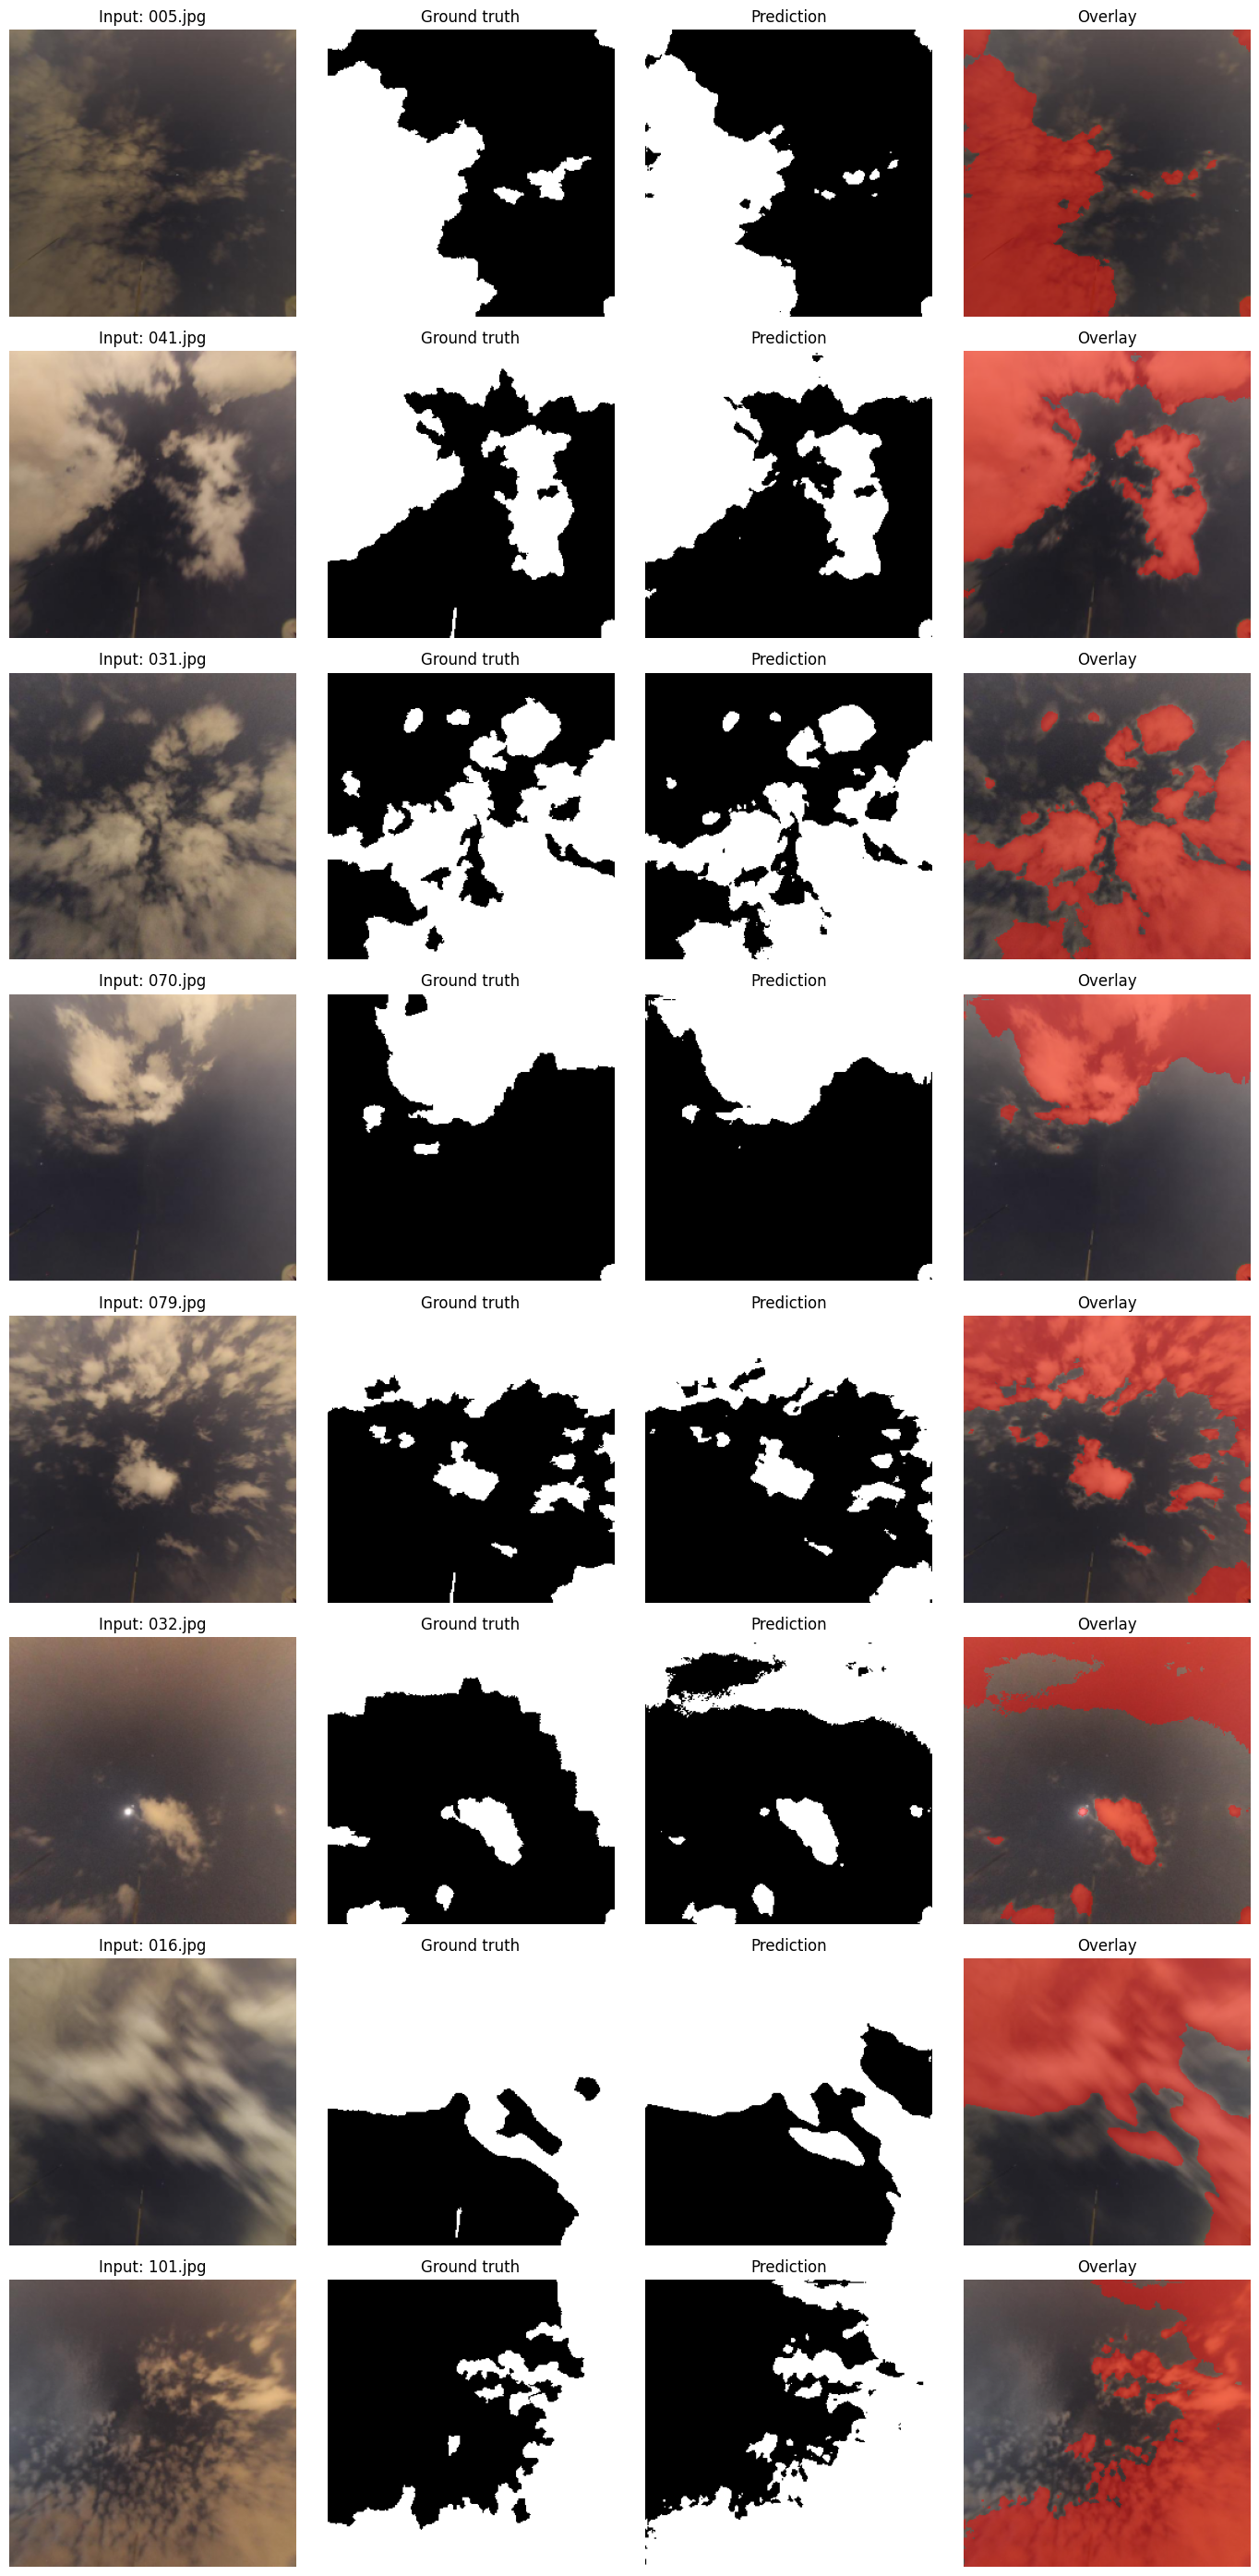

Per-image metrics: /content/resunet_swinseg_outputs/validation_metrics_per_image.csv
Summary metrics: /content/resunet_swinseg_outputs/validation_metrics_summary.csv
Predicted masks: /content/resunet_swinseg_outputs/validation_predicted_masks
Saved predicted masks: 17
test: 1/18 110.jpg Dice=0.9681 IoU=0.9382
test: 2/18 114.jpg Dice=0.9549 IoU=0.9137
test: 3/18 068.jpg Dice=0.9251 IoU=0.8606
test: 4/18 113.jpg Dice=0.7631 IoU=0.6169
test: 5/18 001.jpg Dice=0.6731 IoU=0.5072
test: 6/18 109.jpg Dice=0.5792 IoU=0.4077
test: 7/18 054.jpg Dice=0.8794 IoU=0.7847
test: 8/18 085.jpg Dice=0.9482 IoU=0.9016
test: 9/18 048.jpg Dice=0.9690 IoU=0.9399
test: 10/18 073.jpg Dice=0.9466 IoU=0.8986
test: 11/18 012.jpg Dice=0.9355 IoU=0.8788
test: 12/18 084.jpg Dice=0.9346 IoU=0.8773
test: 13/18 082.jpg Dice=0.8889 IoU=0.7999
test: 14/18 011.jpg Dice=0.9481 IoU=0.9013
test: 15/18 027.jpg Dice=0.8133 IoU=0.6853
test: 16/18 023.jpg Dice=0.8329 IoU=0.7136
test: 17/18 046.jpg Dice=0.9408 IoU=0.8882
test: 18/

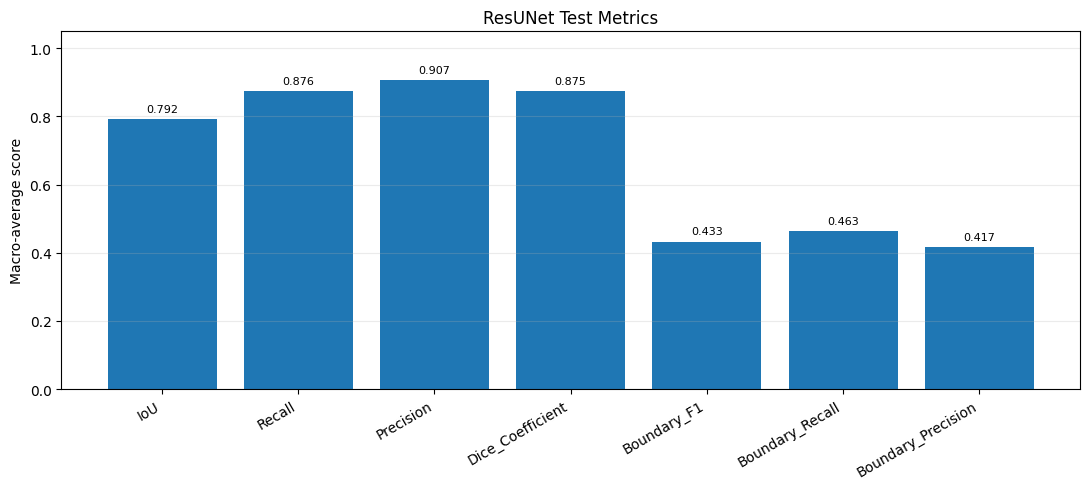

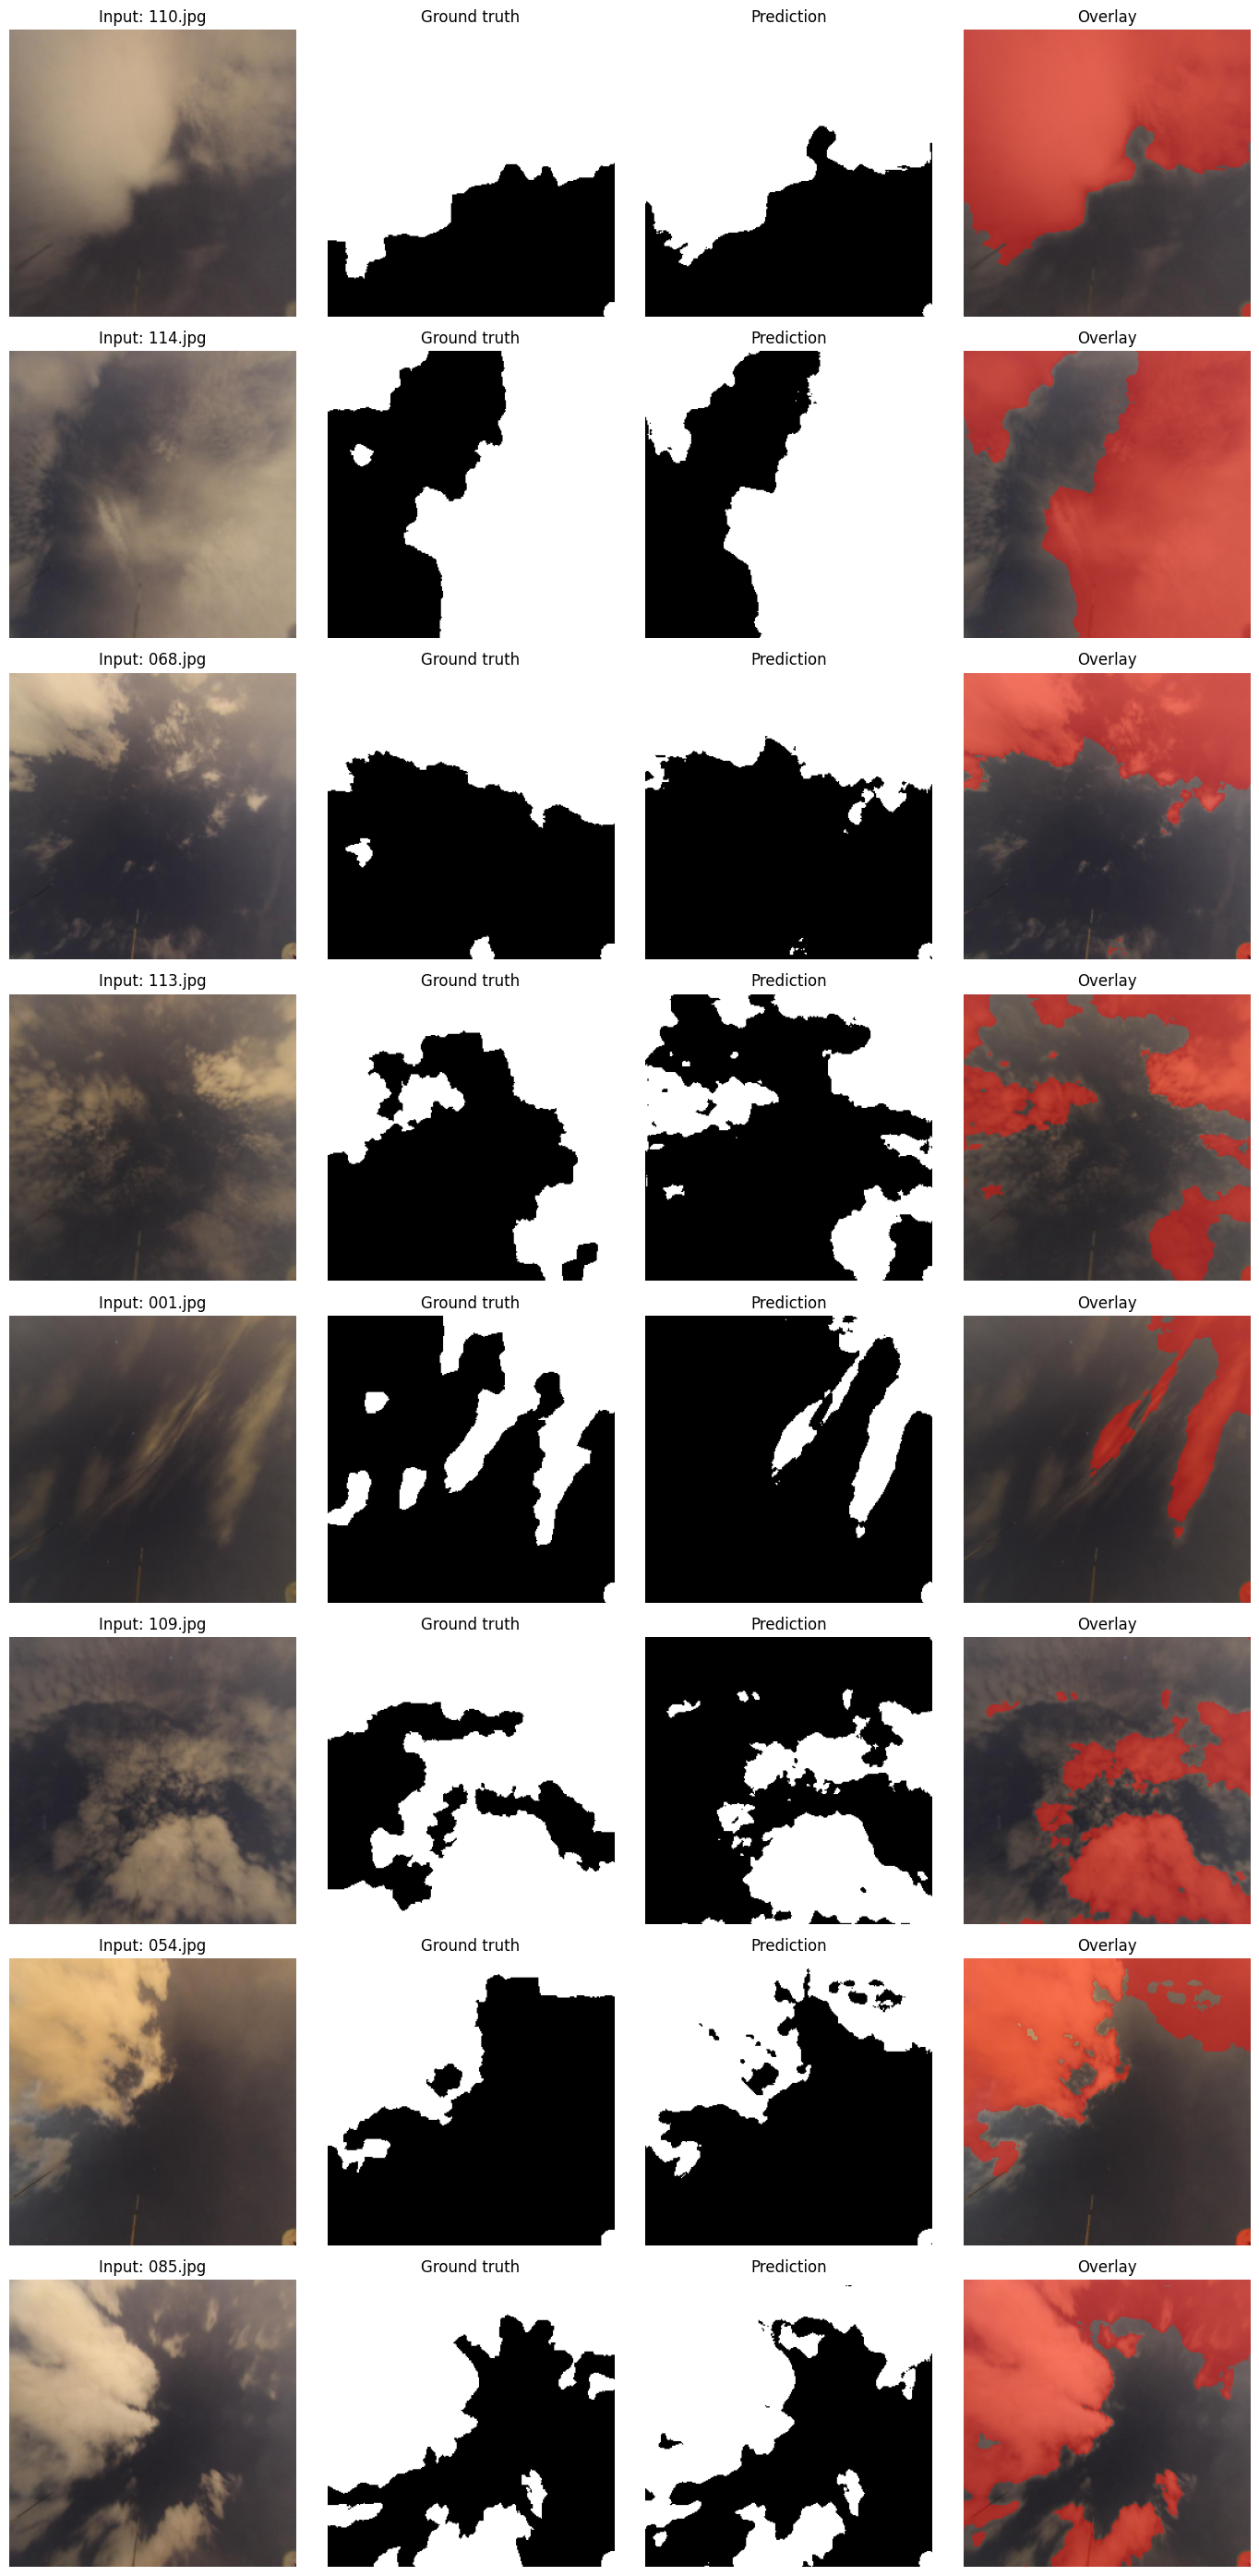

Per-image metrics: /content/resunet_swinseg_outputs/test_metrics_per_image.csv
Summary metrics: /content/resunet_swinseg_outputs/test_metrics_summary.csv
Predicted masks: /content/resunet_swinseg_outputs/test_predicted_masks
Saved predicted masks: 18

FINAL DATASET COUNTS
Training: 80
Validation: 17
Testing: 18
Total paired samples: 115
Test predictions saved: 18
All outputs saved under: /content/resunet_swinseg_outputs


In [7]:
METRIC_COLUMNS = [
    "IoU", "Recall", "Precision", "Dice_Coefficient",
    "Boundary_F1", "Boundary_Recall", "Boundary_Precision"
]

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    ground_truth = np.asarray(y_true, dtype=bool)
    prediction = np.asarray(y_pred, dtype=bool)

    true_positive = int(np.logical_and(ground_truth, prediction).sum())
    false_positive = int(np.logical_and(~ground_truth, prediction).sum())
    false_negative = int(np.logical_and(ground_truth, ~prediction).sum())

    precision = safe_divide(true_positive, true_positive + false_positive)
    recall = safe_divide(true_positive, true_positive + false_negative)
    iou = safe_divide(
        true_positive,
        true_positive + false_positive + false_negative
    )
    dice = safe_divide(
        2 * true_positive,
        2 * true_positive + false_positive + false_negative
    )

    ground_truth_u8 = ground_truth.astype(np.uint8)
    prediction_u8 = prediction.astype(np.uint8)
    erosion_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    ground_truth_boundary = ground_truth_u8 - cv2.erode(
        ground_truth_u8, erosion_kernel, iterations=1
    )
    prediction_boundary = prediction_u8 - cv2.erode(
        prediction_u8, erosion_kernel, iterations=1
    )

    tolerance_size = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (tolerance_size, tolerance_size)
    )
    ground_truth_dilated = cv2.dilate(
        ground_truth_boundary, tolerance_kernel, iterations=1
    ).astype(bool)
    prediction_dilated = cv2.dilate(
        prediction_boundary, tolerance_kernel, iterations=1
    ).astype(bool)

    boundary_precision = safe_divide(
        np.logical_and(prediction_boundary.astype(bool), ground_truth_dilated).sum(),
        prediction_boundary.sum()
    )
    boundary_recall = safe_divide(
        np.logical_and(ground_truth_boundary.astype(bool), prediction_dilated).sum(),
        ground_truth_boundary.sum()
    )
    boundary_f1 = safe_divide(
        2 * boundary_precision * boundary_recall,
        boundary_precision + boundary_recall
    )

    return {
        "IoU": iou,
        "Recall": recall,
        "Precision": precision,
        "Dice_Coefficient": dice,
        "Boundary_F1": boundary_f1,
        "Boundary_Recall": boundary_recall,
        "Boundary_Precision": boundary_precision
    }

def evaluate_split(split_name, sample_pairs):
    prediction_dir = OUTPUT_DIR / f"{split_name}_predicted_masks"
    preview_dir = OUTPUT_DIR / f"{split_name}_prediction_previews"
    prediction_dir.mkdir(parents=True, exist_ok=True)
    preview_dir.mkdir(parents=True, exist_ok=True)

    rows = []
    preview_items = []

    for index, (image_path, mask_path) in enumerate(sample_pairs, start=1):
        image, ground_truth_mask = load_image_mask(image_path, mask_path)
        logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
        probabilities = tf.math.sigmoid(logits).numpy()
        predicted_mask = probabilities >= PREDICTION_THRESHOLD
        ground_truth = ground_truth_mask[..., 0] >= 0.5

        metrics = binary_segmentation_metrics(ground_truth, predicted_mask)
        rows.append({"image_name": Path(image_path).name, **metrics})

        output_name = f"{Path(image_path).stem}_prediction.png"
        output_path = prediction_dir / output_name
        predicted_u8 = predicted_mask.astype(np.uint8) * 255
        if not cv2.imwrite(str(output_path), predicted_u8):
            raise IOError(f"Could not save predicted mask: {output_path}")

        if len(preview_items) < 8:
            overlay = image.copy()
            overlay[predicted_mask] = (
                0.55 * overlay[predicted_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
            )
            preview_items.append((
                Path(image_path).name, image, ground_truth, predicted_mask, overlay
            ))

        print(
            f"{split_name}: {index}/{len(sample_pairs)} "
            f"{Path(image_path).name} "
            f"Dice={metrics['Dice_Coefficient']:.4f} "
            f"IoU={metrics['IoU']:.4f}"
        )

    if len(rows) != len(sample_pairs):
        raise RuntimeError(
            f"Evaluation count mismatch for {split_name}: "
            f"{len(rows)} results for {len(sample_pairs)} samples."
        )

    results_df = pd.DataFrame(rows)
    per_image_path = OUTPUT_DIR / f"{split_name}_metrics_per_image.csv"
    results_df.to_csv(per_image_path, index=False)

    means = results_df[METRIC_COLUMNS].mean()
    stds = (
        results_df[METRIC_COLUMNS].std(ddof=1).fillna(0.0)
        if len(results_df) > 1 else pd.Series(0.0, index=METRIC_COLUMNS)
    )
    summary_df = pd.DataFrame({
        "metric": METRIC_COLUMNS,
        "mean_score": [float(means[column]) for column in METRIC_COLUMNS],
        "std_score": [float(stds[column]) for column in METRIC_COLUMNS],
        "n_images": [len(results_df)] * len(METRIC_COLUMNS)
    })
    summary_path = OUTPUT_DIR / f"{split_name}_metrics_summary.csv"
    summary_df.to_csv(summary_path, index=False)

    print(f"\n{split_name.upper()} MACRO-AVERAGE METRICS")
    for metric in METRIC_COLUMNS:
        print(f"{metric:24s}: {means[metric]:.4f} ± {stds[metric]:.4f}")

    plt.figure(figsize=(11, 5))
    bars = plt.bar(METRIC_COLUMNS, means[METRIC_COLUMNS].to_numpy(dtype=float))
    plt.ylim(0, 1.05)
    plt.ylabel("Macro-average score")
    plt.title(f"ResUNet {split_name.title()} Metrics")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars, means[METRIC_COLUMNS].to_numpy(dtype=float)):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=8
        )
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"{split_name}_metrics.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    if preview_items:
        fig, axes = plt.subplots(
            len(preview_items), 4,
            figsize=(14, 3.5 * len(preview_items)),
            squeeze=False
        )
        for row_index, (name, image, ground_truth, prediction, overlay) in enumerate(preview_items):
            axes[row_index, 0].imshow(image)
            axes[row_index, 0].set_title(f"Input: {name}")
            axes[row_index, 1].imshow(ground_truth, cmap="gray")
            axes[row_index, 1].set_title("Ground truth")
            axes[row_index, 2].imshow(prediction, cmap="gray")
            axes[row_index, 2].set_title("Prediction")
            axes[row_index, 3].imshow(np.clip(overlay, 0, 1))
            axes[row_index, 3].set_title("Overlay")
            for axis in axes[row_index]:
                axis.axis("off")
        plt.tight_layout()
        preview_path = preview_dir / f"{split_name}_prediction_examples.png"
        plt.savefig(preview_path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

    saved_masks = list(prediction_dir.glob("*_prediction.png"))
    if len(saved_masks) != len(sample_pairs):
        raise RuntimeError(
            f"Expected {len(sample_pairs)} predicted masks for {split_name}, "
            f"but found {len(saved_masks)}."
        )

    print("Per-image metrics:", per_image_path)
    print("Summary metrics:", summary_path)
    print("Predicted masks:", prediction_dir)
    print("Saved predicted masks:", len(saved_masks))
    return results_df, summary_df

validation_results, validation_summary = evaluate_split("validation", val_pairs)
test_results, test_summary = evaluate_split("test", test_pairs)

print("\nFINAL DATASET COUNTS")
print("Training:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Testing:", len(test_pairs))
print("Total paired samples:", len(pairs))
print("Test predictions saved:", len(list((OUTPUT_DIR / "test_predicted_masks").glob("*_prediction.png"))))
print("All outputs saved under:", OUTPUT_DIR)
